
# I — Data Audit & Validation

## Objective
Inspect the classification and detection datasets to assess data quality, identify potential issues, and verify dataset structure before preprocessing and model training.


## 1. Dataset Configuration and Overview

The following cells import the audit functions, display the dataset configuration, and locate the classification and detection dataset directories.

In [1]:
import sys
import warnings
import random

import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

warnings.filterwarnings("ignore")

In [2]:
project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root))

In [3]:
import importlib

import src.classification.audit_data as audit_data

audit_data = importlib.reload(audit_data)

from src.classification.audit_data import (
    overview,
    exploration,
    get_class_dirs,
    get_duplicate_images,
    print_class_summary,
    print_image_issues,
    display_sample_images,
    collect_image_shapes,
    print_image_dimensions,
    plot_dimension_counts,
    plot_aspect_ratios,
)


In [4]:
overview()

Project directory: /home/houssam/Documents/brief-5
Dataset directory: /home/houssam/Documents/brief-5/Data/origine
Dataset exists: True
Image size: (224, 224)
Supported extensions: {'.png', '.bmp', '.jpeg', '.jpg'}


In [5]:
classification, detection = exploration()

Number of Paths in Data folder: 2
classification
detection



## 2. Classification Dataset Audit


### 2.1. Explore Dataset Structure and Classes

This function returns the class directories inside the classification dataset.

In [6]:
class_dirs = get_class_dirs(classification)

### 2.2. Count Images per Class

This function prints the number of files, supported images, and training or testing prefixes for every class.

In [7]:
print_class_summary(class_dirs)

Number of classes: 4
Class: glioma
  Total files: 1621
  Supported images: 1621
  Training prefix (Tr-): 1321
  Testing prefix (Te-): 300

Class: meningioma
  Total files: 1645
  Supported images: 1645
  Training prefix (Tr-): 1339
  Testing prefix (Te-): 306

Class: notumor
  Total files: 2000
  Supported images: 2000
  Training prefix (Tr-): 1595
  Testing prefix (Te-): 405

Class: pituitary
  Total files: 1757
  Supported images: 1757
  Training prefix (Tr-): 1457
  Testing prefix (Te-): 300

Total of images : 7023
From 7023 of files


### 2.3. Validate File Extensions and Image Readability

This function counts unsupported files and detects images that OpenCV cannot read.

In [8]:
print_image_issues(class_dirs)

Total supported image files: 7023
Unreadable images: 0
Unsupported files: 0


### 2.4. Detect Duplicate Images

Images with identical file contents are grouped using their SHA-256 hash. This helps identify duplicated samples across classification classes.

Duplicate image groups: 194

Duplicate example 1 | Hash: 7a7fcfb55378e4367cb3f163dc510df7e4b5f95d8fee5e4407b6ef397d56e243
  /home/houssam/Documents/brief-5/Data/origine/classification/notumor/Tr-no_0244.jpg
  /home/houssam/Documents/brief-5/Data/origine/classification/notumor/Tr-no_1139.jpg

Duplicate example 2 | Hash: f2d9f0979df98ce2e4aab669d3c141ca02ebce9eb15775267bfd6d4eae2a7d7f
  /home/houssam/Documents/brief-5/Data/origine/classification/notumor/Te-no_0022.jpg
  /home/houssam/Documents/brief-5/Data/origine/classification/notumor/Te-no_0075.jpg
  /home/houssam/Documents/brief-5/Data/origine/classification/notumor/Tr-no_0069.jpg
  /home/houssam/Documents/brief-5/Data/origine/classification/notumor/Tr-no_0338.jpg
  /home/houssam/Documents/brief-5/Data/origine/classification/notumor/Tr-no_1084.jpg

Duplicate example 3 | Hash: 24f09f91af40e42f2798bbc29df353ce17e6a0c0b533fb923b2fa8f75df6b496
  /home/houssam/Documents/brief-5/Data/origine/classification/meningioma/Tr-me_0176.jpg
  /home

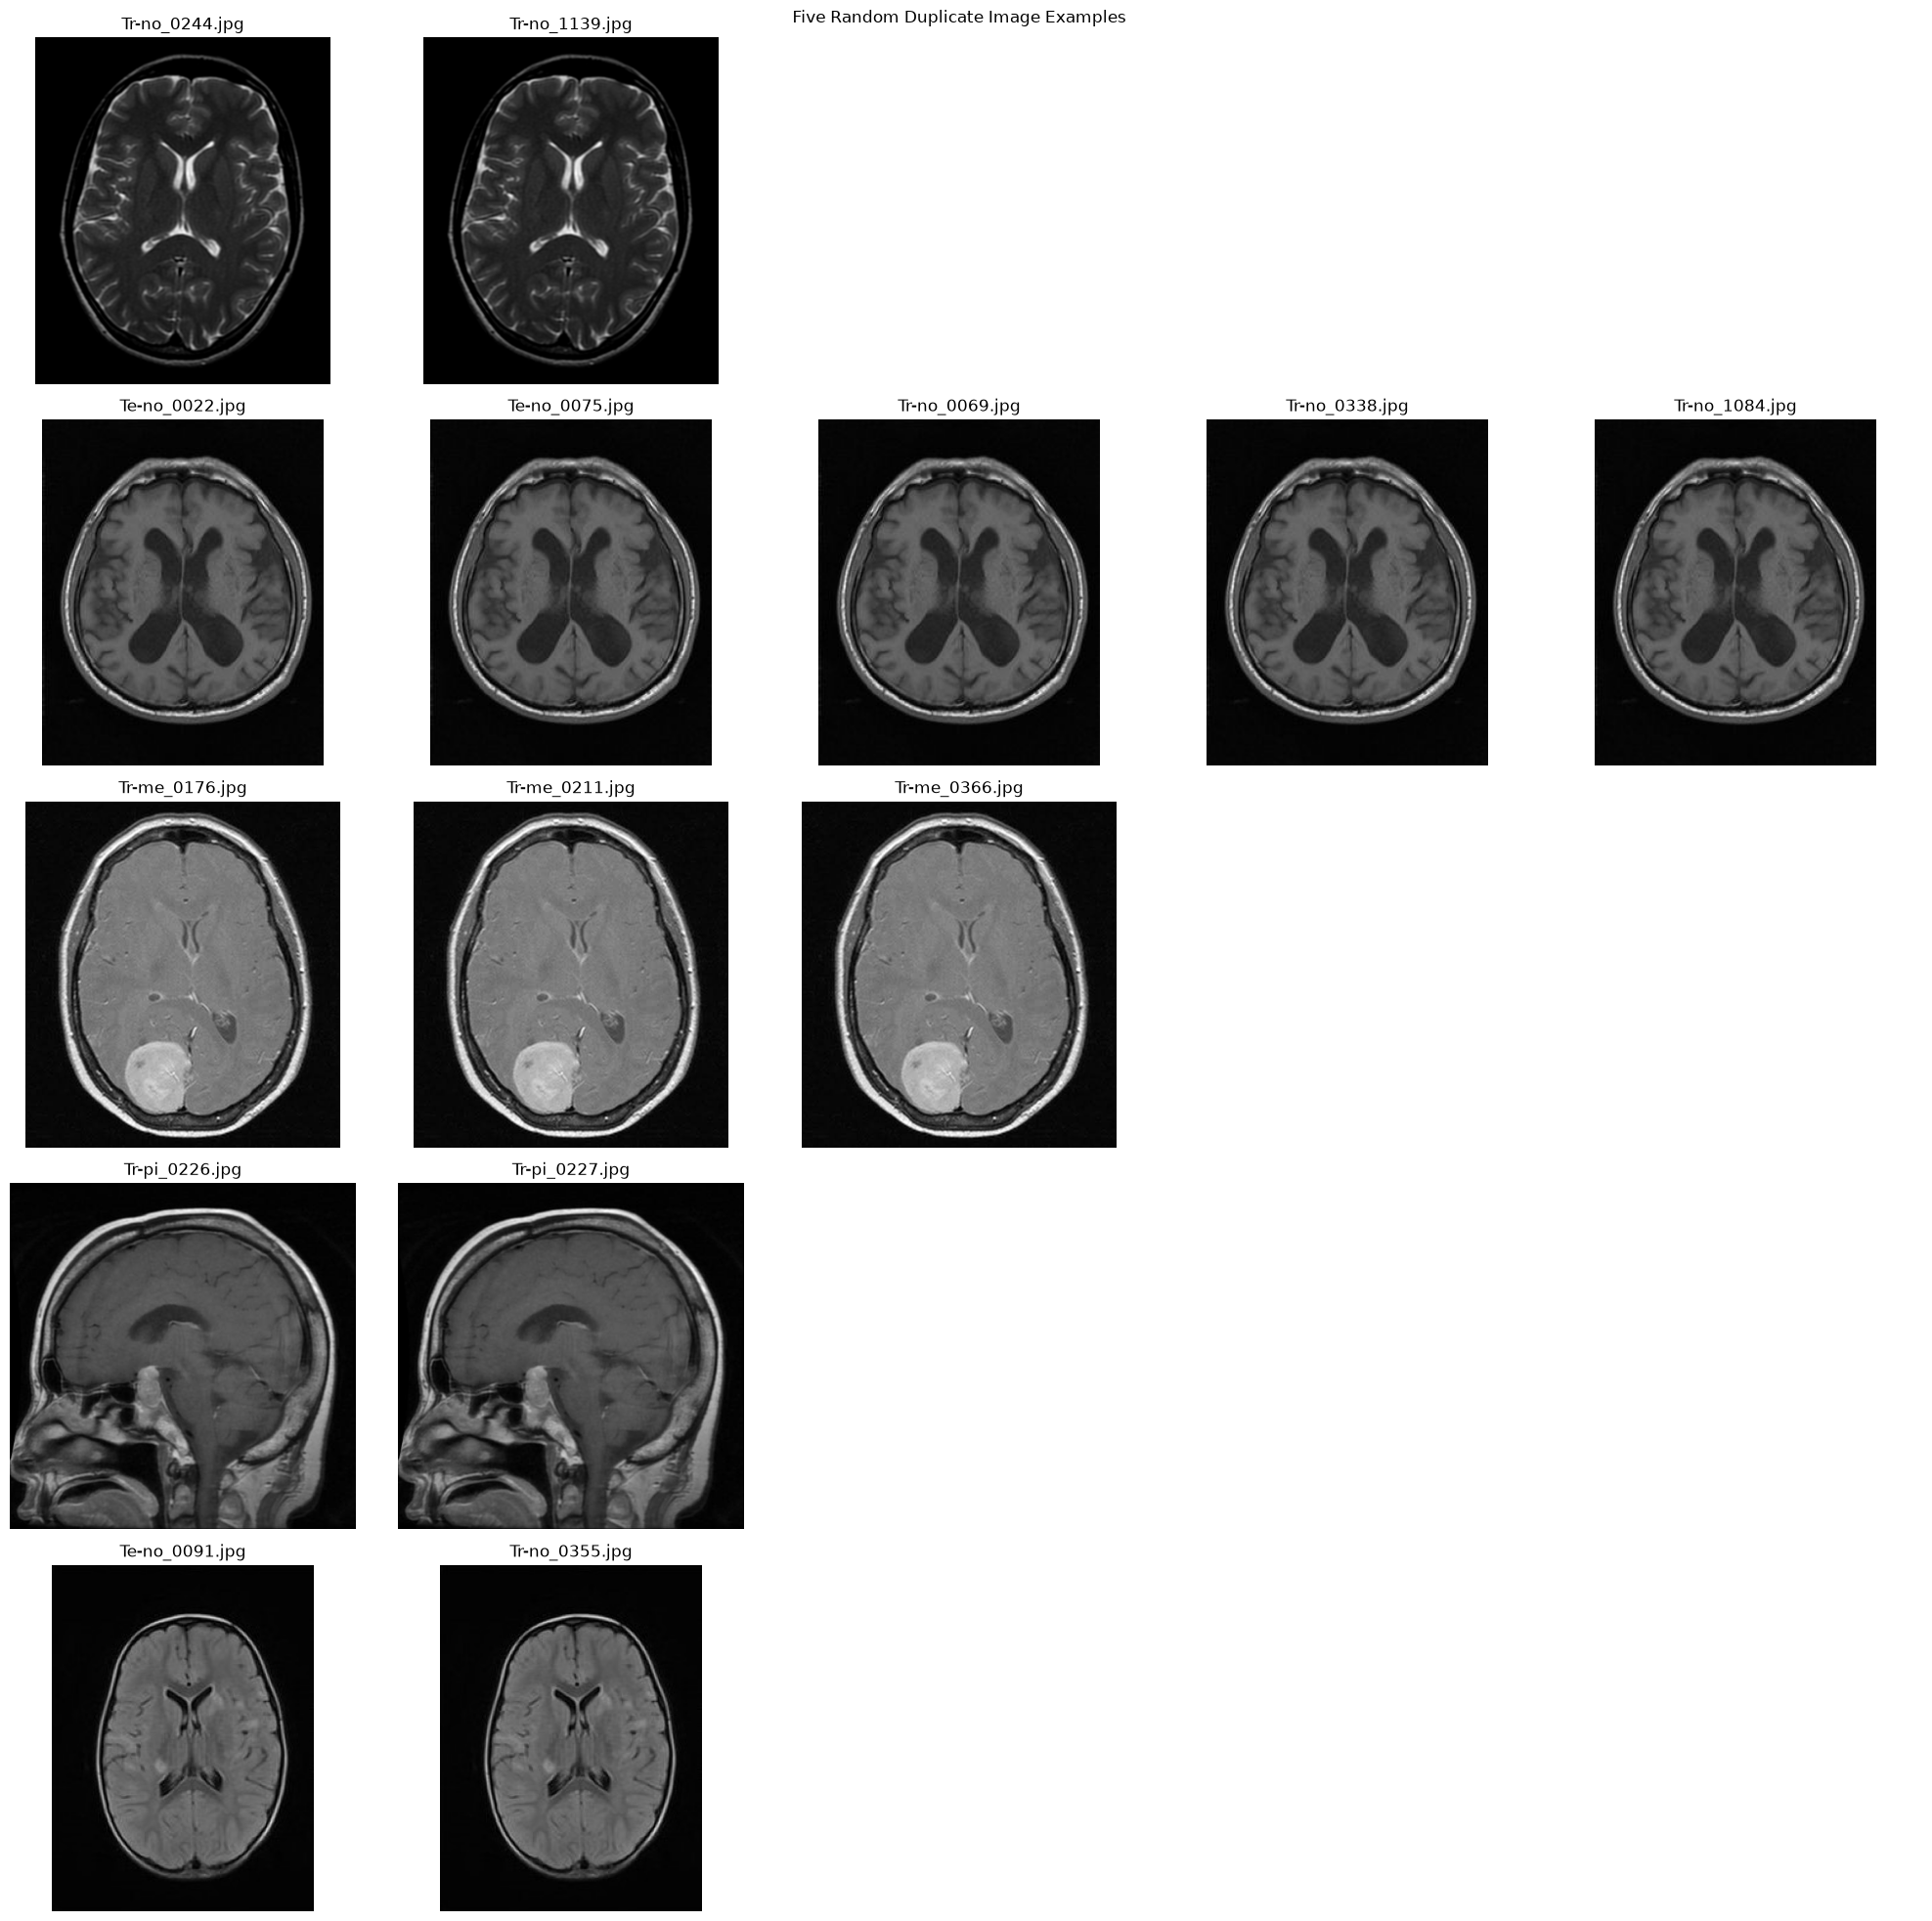

In [9]:
duplicate_images = get_duplicate_images(classification)

print("Duplicate image groups:", len(duplicate_images))

random.seed(42)
example_groups = random.sample(
    list(duplicate_images.items()),
    k=min(5, len(duplicate_images)),
)

for group_number, (digest, image_paths) in enumerate(example_groups, start=1):
    print(f"\nDuplicate example {group_number} | Hash: {digest}")
    for image_path in image_paths:
        print(f"  {image_path}")

if example_groups:
    max_images = max(len(image_paths) for _, image_paths in example_groups)
    figure, axes = plt.subplots(
        len(example_groups),
        max_images,
        figsize=(4 * max_images, 4 * len(example_groups)),
        squeeze=False,
    )

    for row, (digest, image_paths) in enumerate(example_groups):
        for column, image_path in enumerate(image_paths):
            axes[row, column].imshow(Image.open(image_path))
            axes[row, column].set_title(image_path.name)
            axes[row, column].axis("off")

        for column in range(len(image_paths), max_images):
            axes[row, column].axis("off")

        axes[row, 0].set_ylabel(
            f"Example {row + 1}\n{digest[:12]}...",
            rotation=0,
            labelpad=45,
            va="center",
        )

    figure.suptitle("Five Random Duplicate Image Examples")
    plt.tight_layout()
    plt.show()

### 2.5. Display Representative Images

This function displays up to three supported sample images from each class for a visual quality check.

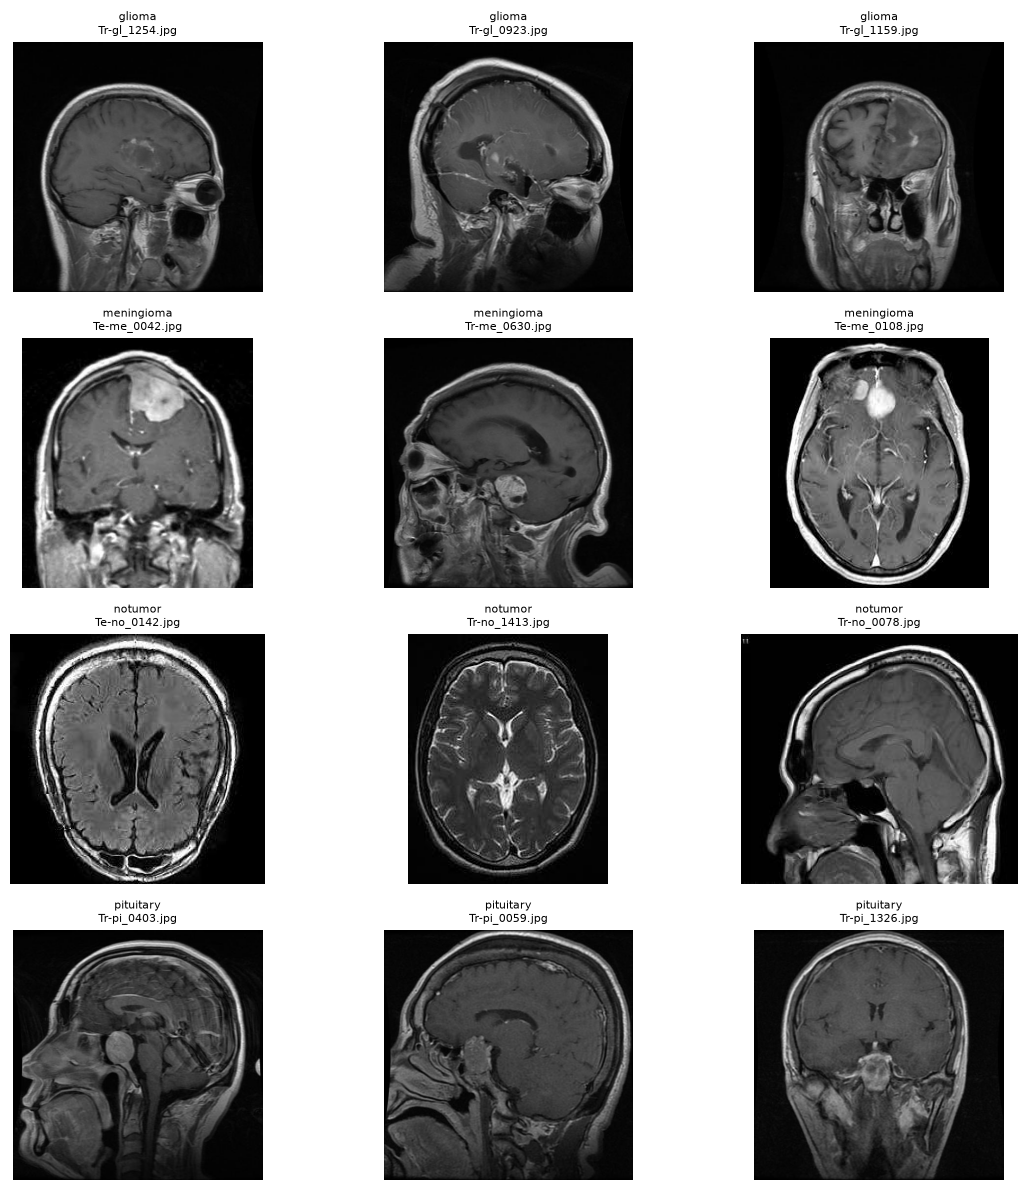

In [10]:
display_sample_images(class_dirs)

### 2.6. Analyze Image Dimensions

This function reads valid images and collects their height and width frequencies for later reporting and plotting.

In [11]:
image_shapes = collect_image_shapes(class_dirs)

### 2.7. Report Common Image Dimensions

This function prints the number of unique dimensions and the minimum, maximum, and most common image sizes.

In [12]:
print_image_dimensions(image_shapes)

Number of unique image dimensions: 387

Most common dimensions:
(512, 512): 4742 images
(225, 225): 332 images
(630, 630): 90 images
(236, 236): 81 images
(251, 201): 58 images
(221, 228): 51 images
(217, 232): 50 images
(168, 300): 49 images
(442, 442): 46 images
(198, 150): 44 images

Minimum width: 150
Maximum width: 1920
Minimum height: 168
Maximum height: 1446


### 2.8. Plot Dimension Distribution

This function plots the ten most frequent image dimensions to make size variation easier to compare.

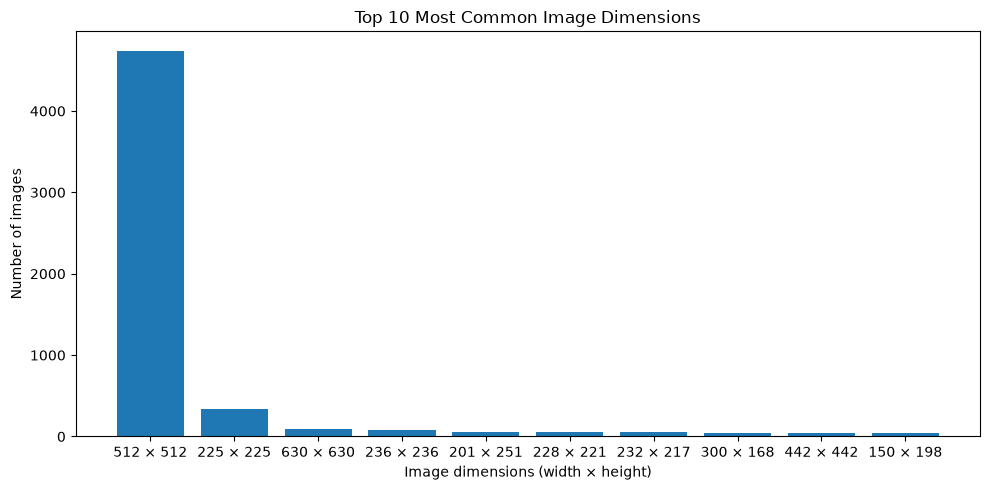

In [13]:
plot_dimension_counts(image_shapes)

### 2.9. Plot Aspect-Ratio Distribution

This function plots the distribution of image width-to-height ratios to reveal unusually wide or tall images.

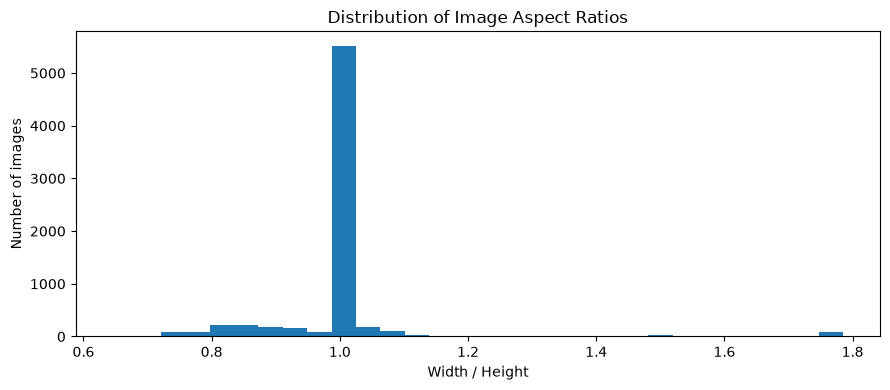

Minimum aspect ratio: 0.645
Maximum aspect ratio: 1.786


In [14]:
plot_aspect_ratios(image_shapes)